# 10 — Numerical Apsidal Precession Sweep

**Question.** How much *spurious* apsidal precession does each integrator produce on an eccentric two-body orbit, and what
timestep (or tolerance) is needed to measure the 1PN precession to 1%?

**Setup.** Sun + Mercury-like planet (a = 5.7909e10 m, planet mass 3.3011e23 kg, Sun mass `orbit.M_SUN`), started at
perihelion; 100 years (~415 orbits); `gr=False` for the spurious rate, `gr=True` for a consistency check against the analytic
1PN rate `6πGM / (c² a (1−e²))` per orbit. Integrators: RK4, Leapfrog, Yoshida4, Hermite (fixed step, dt = 1/16 h … 16 h; Leapfrog
extended down to 28 s) and RK45 (tolerance 1e-5 … 1e-13). Eccentricity e = 0.05, 0.1, 0.2056 (Mercury), 0.3, 0.4, 0.5, 0.6.

**Criterion.** "Measures 1PN to 1%" is taken to mean the spurious (GR-off) rate is at most 1% of the 1PN rate for that e, with no
baseline subtraction.

**Cost model** (pairwise-force sweeps per step): RK4 4, Leapfrog 1, Yoshida4 3, Hermite 4 (two acceleration + two jerk passes),
RK45 6 per accepted and 7 per rejected step. This counts sweeps, not wall time (jerk sweeps cost more than acceleration sweeps).

**Estimator.** Notebook 09 fitted the Runge–Lenz angle from finite-difference velocities; section 1 shows that estimator has its own
bias. Here the perihelion longitude is read off once per orbit at the interpolated periapsis (`python/precession.py`).

**Data.** The sweep (672 runs) is produced by `python/precession_sweep.py` (about 15 minutes on 8 cores) and read from
`results/precession_sweep/numerical_precession.csv`.

**Related work (not novel).** Spurious precession of symplectic and non-symplectic integrators on the Kepler problem is documented, e.g. a comparison of
fourth-order methods (Forest–Ruth vs Runge–Kutta–Nyström) in [arXiv:math-ph/0608012](https://arxiv.org/abs/math-ph/0608012), the high-eccentricity behaviour of
Wisdom–Holman schemes in the WHFast paper [arXiv:1506.01084](https://arxiv.org/abs/1506.01084), and a Mercury precession example with a Taylor integrator
in the [heyoka.py docs](https://nbviewer.org/github/bluescarni/heyoka.py/blob/v6.1.0/doc/notebooks/mercury_precession.ipynb). These were located by a web search and
identified from titles/snippets only; read them before citing.

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == 'examples':
    os.chdir('..')
sys.path.insert(0, '.')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, math
import orbit
from python import precession as P
from python import precession_analysis as A
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
print('orbit', orbit.__version__, '| period', P.period() / 86400, 'days | orbits in 100 yr', 100 * 365.25 * 86400 / P.period())

orbit 2.0.0 | period 87.96894242334739 days | orbits in 100 yr 415.2033546592472


## 1. The estimator: control on an exact Kepler ellipse

An exact Newtonian ellipse has zero precession, so any non-zero value returned for one is estimator error. The last two columns show notebook 09's estimator (finite-difference velocity, Runge–Lenz angle, one global line fit) next to the periapsis estimator used here.

In [2]:
GM = orbit.G * orbit.M_SUN
def nb09_estimator(rel, t, dt_out):
    v = (rel[2:] - rel[:-2]) / (2 * dt_out); r = rel[1:-1]
    rh = r / np.linalg.norm(r, axis=1, keepdims=True)
    A_vec = np.cross(v, np.cross(r, v)) / GM - rh
    ang = np.unwrap(np.arctan2(A_vec[:, 1], A_vec[:, 0]))
    return np.polyfit(t[1:-1], ang, 1)[0] * P.CENTURY_S * P.ARCSEC

rows = []
for e in (0.05, 0.2056, 0.6):
    for dt_h in (1, 4, 24):
        dt = dt_h * 3600.0
        t = np.arange(1, int(100 * 365.25 * 86400 / dt)) * dt
        rel = P.kepler_relative_positions(t, e)
        rows.append(dict(e=e, output_spacing_h=dt_h,
                         periapsis_estimator=P.precession_rate(t, rel)[0],
                         notebook09_estimator=nb09_estimator(rel, t, dt)))
print("Apparent precession of an EXACT Kepler ellipse (true value 0), arcsec/century")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f'{x:+.5f}'))

Apparent precession of an EXACT Kepler ellipse (true value 0), arcsec/century
       e  output_spacing_h  periapsis_estimator  notebook09_estimator
+0.05000                 1             -0.00000              +0.03457
+0.05000                 4             +0.00000              +0.58979
+0.05000                24             -0.00911             +22.73139
+0.20560                 1             -0.00000              +0.00909
+0.20560                 4             +0.00000              +0.15425
+0.20560                24             -0.07164              +5.87846
+0.60000                 1             -0.00000              +0.00867
+0.60000                 4             +0.00032              +0.14006
+0.60000                24            -19.94063              +4.15468


## 2. Load the sweep; reproduce one case live

`estimator_floor` is the estimator applied to an exact ellipse sampled at that run's own snapshot times.

In [3]:
df = A.load()
print(len(df), 'runs;', df.integrator.nunique(), 'integrators;', df.e.nunique(), 'eccentricities')
fx = df[df.integrator != 'RK45']
print('max snapshot spacing, fixed-step runs with dt<=4h: %.2f h' % fx[fx.dt_s <= 4*3600].max_output_spacing_h.max())

# Is the estimator accurate where it matters? GR-off runs whose spurious rate is within a factor 3 of the 1% threshold.
v = df[df.gr == 0].copy()
v['thr'] = [0.01 * P.gr_rate_arcsec_per_century(e) for e in v.e]
near = v[(v.rate_arcsec_per_century.abs() > v.thr / 3) & (v.rate_arcsec_per_century.abs() < v.thr * 3)]
print('runs within x3 of the 1%% threshold: %d; max |estimator floor| there = %.1e arcsec/century (%.3f %% of the threshold)'
      % (len(near), near.estimator_floor.abs().max(), 100 * (near.estimator_floor.abs() / near.thr).max()))
print('  by integrator, max floor / threshold (%):', (100 * (near.estimator_floor.abs() / near.thr)).groupby(near.integrator).max().round(3).to_dict())
meas = v[v.rate_arcsec_per_century.abs() > A.FLOOR]
bad = meas[meas.estimator_floor.abs() > 0.01 * meas.rate_arcsec_per_century.abs()]
print('runs (|rate| > %g) where the floor exceeds 1%% of the measured rate: %d of %d, all with |rate| <= %.3g arcsec/century'
      % (A.FLOOR, len(bad), len(meas), bad.rate_arcsec_per_century.abs().max()))
print('  RK45 snapshots are the accepted steps (irregular, up to %.1f h apart), fixed-step runs with dt<=4h are exactly 4 h' % df[df.integrator == "RK45"].max_output_spacing_h.max())

# live reproduction of one case: RK4, dt = 1 h, e = 0.2056, GR off and on
import tempfile
path = tempfile.mktemp(suffix='.json'); P.write_system(path, 0.2056)
for gr in (False, True):
    res = orbit.simulate(path, steps=876600, dt=3600.0, integrator=orbit.Integrator.RK4, stride=4, gr=gr)
    rate, se, n = P.precession_rate(*P.rel_positions(res))
    csv = df[(df.integrator=='RK4') & (df.dt_s==3600) & (df.e==0.2056) & (df.gr==int(gr))].rate_arcsec_per_century.iloc[0]
    print(f'RK4 dt=1h e=0.2056 gr={gr!s:5}: live {rate:+.6f} +- {se:.1e}   CSV {csv:+.6f}   ({n} orbits)')
print('analytic 1PN rate at e=0.2056: %.5f arcsec/century' % P.gr_rate_arcsec_per_century(0.2056))

672 runs; 5 integrators; 7 eccentricities
max snapshot spacing, fixed-step runs with dt<=4h: 4.00 h
runs within x3 of the 1% threshold: 32; max |estimator floor| there = 1.9e-03 arcsec/century (0.345 % of the threshold)
  by integrator, max floor / threshold (%): {'Hermite': 0.103, 'Leapfrog': 0.083, 'RK4': 0.044, 'RK45': 0.345, 'Yoshida4': 0.019}
runs (|rate| > 1e-05) where the floor exceeds 1% of the measured rate: 47 of 311, all with |rate| <= 1.13e+03 arcsec/century
  RK45 snapshots are the accepted steps (irregular, up to 24.0 h apart), fixed-step runs with dt<=4h are exactly 4 h


RK4 dt=1h e=0.2056 gr=False: live +0.004121 +- 1.1e-05   CSV +0.004121   (415 orbits)


RK4 dt=1h e=0.2056 gr=True : live +42.984344 +- 1.1e-05   CSV +42.984344   (415 orbits)
analytic 1PN rate at e=0.2056: 42.98024 arcsec/century


## 3. Consistency check: GR-on minus GR-off against the analytic 1PN rate

At fine timesteps (900 s; RK45 tolerance 1e-12) every integrator should reproduce the analytic rate.

In [4]:
chk = A.gr_check(df)
print(chk.pivot(index='e', columns='integrator', values='rel_error_pct').to_string(float_format=lambda x: f'{x:+.5f}'))
print('\nmax |relative error| = %.5f %%' % chk.rel_error_pct.abs().max())

integrator  Hermite  Leapfrog      RK4     RK45  Yoshida4
e                                                        
0.0500     -0.00004  +0.00006 -0.00002 -0.00003  -0.00012
0.1000     -0.00005  +0.00007 -0.00002 -0.00004  -0.00012
0.2056     -0.00006  +0.00009 -0.00004 -0.00005  -0.00015
0.3000     -0.00008  +0.00014 -0.00004 -0.00006  -0.00018
0.4000     -0.00006  +0.00027 -0.00002 -0.00009  -0.00021
0.5000     -0.00023  +0.00088 -0.00016 -0.00013  -0.00033
0.6000     +0.00100  +0.00425 +0.00111 -0.00021  -0.00054

max |relative error| = 0.00425 %


## 4. Scaling of the spurious rate

Power-law fit `|rate| = C(e) · dt^p` over the asymptotic regime (1e-3 < |rate| < 2e3 arcsec/century), and the eccentricity dependence at dt = 2 h as `(1−e²)^−q`.

In [5]:
fits = A.fit_scaling(df)
print('Fitted order p:'); print(fits.pivot(index='e', columns='integrator', values='order_p').round(3).to_string())
print('\nSign of the spurious rate (+ prograde, - retrograde):')
print(fits.groupby('integrator').sign.agg(lambda s: sorted(set(s))).to_string())
print('\nEccentricity dependence at dt = 2 h, |rate| ~ (1-e^2)^-q:'); print(A.fit_eccentricity(df).round(3).to_string(index=False))
fits.to_csv('results/precession_sweep/scaling_fits.csv', index=False)

Fitted order p:
integrator  Hermite  Leapfrog    RK4  Yoshida4
e                                             
0.0500        4.000       2.0  3.999     4.000
0.1000        4.000       2.0  3.999     4.000
0.2056        4.000       2.0  3.998     4.000
0.3000        4.000       2.0  3.997     4.000
0.4000        4.001       2.0  3.996     4.001
0.5000        4.003       2.0  4.005     4.005
0.6000        4.006       2.0  4.008     4.009

Sign of the spurious rate (+ prograde, - retrograde):
integrator
Hermite      [1]
Leapfrog    [-1]
RK4          [1]
Yoshida4     [1]

Eccentricity dependence at dt = 2 h, |rate| ~ (1-e^2)^-q:
integrator     q  max_abs_ln_residual
       RK4 8.540                0.088
  Leapfrog 3.194                0.003
  Yoshida4 8.256                0.073
   Hermite 8.258                0.073


## 5. Timestep / tolerance and cost needed for a 1% GR measurement

Log–log interpolation to the point where the spurious rate equals 1% of the 1PN rate. RK45's parameter is the tolerance (`atol = rtol`).

In [6]:
th = A.thresholds(df, 0.01)
th.to_csv('results/precession_sweep/threshold_1pct.csv', index=False)
print('Timestep dt* (s) for fixed-step methods, tolerance for RK45:')
print(th.pivot(index='e', columns='integrator', values='param').to_string(float_format=lambda x: f'{x:.4g}'))
print('\nForce sweeps per orbit at that setting:')
print(th.pivot(index='e', columns='integrator', values='sweeps_per_orbit').to_string(float_format=lambda x: f'{x:,.0f}'))
m = th[th.e == 0.2056].set_index('integrator')
print('\nMercury-like e = 0.2056: 1%% threshold = %.3f arcsec/century' % m.threshold.iloc[0])
print(m[['param', 'sweeps_100yr', 'sweeps_per_orbit']].to_string(float_format=lambda x: f'{x:,.4g}'))

# Sensitivity: subtract each run's estimator floor from its rate and redo the thresholds
dfc = df.copy(); dfc['rate_arcsec_per_century'] = dfc.rate_arcsec_per_century - dfc.estimator_floor
thc = A.thresholds(dfc, 0.01)
mm = th.merge(thc, on=['integrator', 'e'], suffixes=('', '_corrected'))
print('\nEffect of correcting for the estimator floor (max over e):')
print('  threshold parameter change: %.2f %%   cost change: %.2f %%' % (
    (mm.param_corrected / mm.param - 1).abs().max() * 100, (mm.sweeps_per_orbit_corrected / mm.sweeps_per_orbit - 1).abs().max() * 100))

Timestep dt* (s) for fixed-step methods, tolerance for RK45:
integrator   Hermite  Leapfrog       RK4      RK45  Yoshida4
e                                                           
0.0500     1.024e+04     66.73 1.265e+04 1.077e-09      5330
0.1000     1.007e+04     66.16 1.242e+04 8.636e-10      5241
0.2056          9372     63.75  1.15e+04 5.742e-10      4880
0.3000          8446     60.22  1.03e+04 5.864e-10      4398
0.4000          7256     55.12      8793 6.762e-10      3778
0.5000          5945     48.69      7158 8.564e-10      3095
0.6000          4591     41.01      5497 1.396e-09      2390

Force sweeps per orbit at that setting:
integrator  Hermite  Leapfrog   RK4  RK45  Yoshida4
e                                                  
0.0500        2,970   113,906 2,404   715     4,278
0.1000        3,020   114,878 2,448   754     4,350
0.2056        3,244   119,225 2,643   820     4,672
0.3000        3,600   126,216 2,950   864     5,185
0.4000        4,190   137,898 3,457  


Effect of correcting for the estimator floor (max over e):
  threshold parameter change: 0.31 %   cost change: 0.05 %


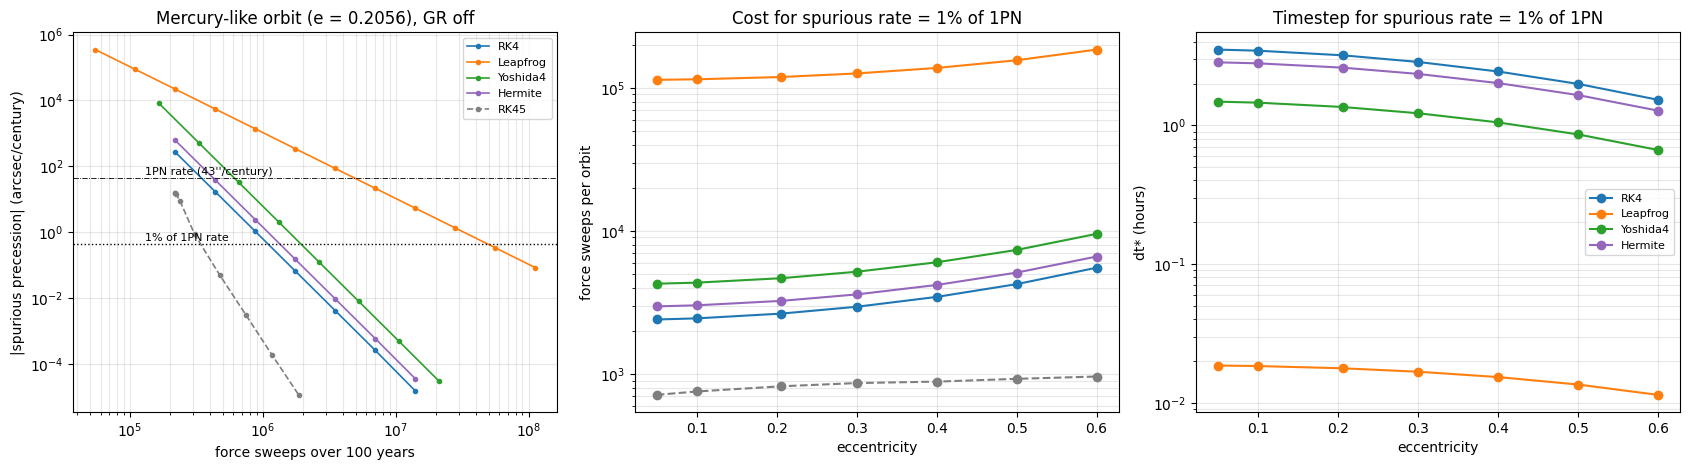

saved results/precession_sweep/summary.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
col = {'RK4': '#1f77b4', 'Leapfrog': '#ff7f0e', 'Yoshida4': '#2ca02c', 'Hermite': '#9467bd', 'RK45': '#7f7f7f'}
d0 = df[(df.gr == 0)]
ax = axes[0]; e0 = 0.2056
for integ in A.ALL:
    g = d0[(d0.integrator == integ) & (d0.e == e0)].sort_values('force_sweeps')
    y = np.abs(g.rate_arcsec_per_century.values); keep = y > A.FLOOR
    ax.loglog(g.force_sweeps.values[keep], y[keep], marker='o', ms=3, lw=1.2, color=col[integ], label=integ, ls='--' if integ == 'RK45' else '-')
thr = 0.01 * P.gr_rate_arcsec_per_century(e0)
ax.axhline(thr, color='k', lw=1, ls=':'); ax.text(1.3e5, thr * 1.25, '1% of 1PN rate', fontsize=8)
ax.axhline(P.gr_rate_arcsec_per_century(e0), color='k', lw=0.6, ls='-.'); ax.text(1.3e5, P.gr_rate_arcsec_per_century(e0) * 1.25, '1PN rate (43\'\'/century)', fontsize=8)
ax.set_xlabel('force sweeps over 100 years'); ax.set_ylabel("|spurious precession| (arcsec/century)")
ax.set_title('Mercury-like orbit (e = 0.2056), GR off'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
ax = axes[1]
for integ in A.ALL:
    g = th[th.integrator == integ].dropna(subset=['sweeps_per_orbit'])
    ax.semilogy(g.e, g.sweeps_per_orbit, marker='o', color=col[integ], label=integ, ls='--' if integ == 'RK45' else '-')
ax.set_xlabel('eccentricity'); ax.set_ylabel('force sweeps per orbit'); ax.set_title('Cost for spurious rate = 1% of 1PN'); ax.grid(True, which='both', alpha=0.3)
ax = axes[2]
for integ in A.FIXED:
    g = th[th.integrator == integ].dropna(subset=['param'])
    ax.semilogy(g.e, g.param / 3600.0, marker='o', color=col[integ], label=integ)
ax.set_xlabel('eccentricity'); ax.set_ylabel('dt* (hours)'); ax.set_title('Timestep for spurious rate = 1% of 1PN'); ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('results/precession_sweep/summary.png', dpi=150); plt.show()
print('saved results/precession_sweep/summary.png')

## 6. Cross-check against REBOUND (Newtonian baseline and 1PN with a custom force)

**Limitation.** REBOUNDx (with its built-in 1PN modules) is *not installed* here and could not be installed in this environment, so this is **not** a
comparison against REBOUNDx. What this cell does with plain REBOUND 5: (a) IAS15 and WHFast on the Newtonian problem, giving an independent
reference for "zero precession" and for WHFast's own spurious rate under the same estimator; (b) IAS15 with the engine's 1PN formula implemented as a
Python force in REBOUND, which checks the integration of the 1PN term by an independent integrator but **not** an independent implementation of the 1PN physics.

In [8]:
import rebound, time
e0 = 0.2056; a0 = P.A_MERCURY; rp = a0 * (1 - e0); vp = math.sqrt(P.mu_total() * (1 + e0) / rp)
GM_ = orbit.G * orbit.M_SUN; C2 = orbit.C_LIGHT ** 2

def gr_force(reb_sim):
    p = reb_sim.contents.particles; s, m = p[0], p[1]
    rx, ry, rz = m.x - s.x, m.y - s.y, m.z - s.z
    vx, vy, vz = m.vx - s.vx, m.vy - s.vy, m.vz - s.vz
    r = math.sqrt(rx*rx + ry*ry + rz*rz); v2 = vx*vx + vy*vy + vz*vz; rdv = rx*vx + ry*vy + rz*vz
    f = GM_ / (C2 * r**3); k = 4 * GM_ / r - v2
    m.ax += f * (k * rx + 4 * rdv * vx); m.ay += f * (k * ry + 4 * rdv * vy); m.az += f * (k * rz + 4 * rdv * vz)

def rebound_rate(integrator, dt=None, gr=False, years=100, spacing=2 * 3600.0):
    sim = rebound.Simulation(); sim.G = orbit.G; sim.integrator = integrator
    sim.add(m=orbit.M_SUN); sim.add(m=P.M_MERCURY, x=rp, vy=vp)
    if dt: sim.dt = dt
    if gr:
        sim.additional_forces = gr_force; sim.force_is_velocity_dependent = 1
    tend = years * 365.25 * 86400
    ts, rels = [], []
    while sim.t < tend:
        # exact_finish_time=1: IAS15 shortens a step to land on the output time, so samples are 2 h apart
        # (with exact_finish_time=0 its steps reach ~100 h at apoapsis and the periapsis fit is far too coarse)
        sim.integrate(sim.t + spacing, exact_finish_time=1)
        p = sim.particles
        ts.append(sim.t); rels.append((p[1].x - p[0].x, p[1].y - p[0].y, p[1].z - p[0].z))
    t, rel = np.array(ts), np.array(rels)
    assert np.all(np.diff(t) > 0)
    return P.precession_rate(t, rel), P.estimator_floor(t, e0), float(np.diff(t).max() / 3600.0)

rows = []
# 20 years (~83 orbits) for the two IAS15 runs: the Python force callback makes 100 years slow, and the periapsis fit already
# has a standard error of ~1e-5 arcsec/century on this many orbits
for label, kw in [('REBOUND IAS15, Newtonian, 20 yr', dict(integrator='ias15', years=20)),
                  ('REBOUND WHFast dt=1h, Newtonian, 100 yr', dict(integrator='whfast', dt=3600.0, years=100)),
                  ('REBOUND IAS15 + 1PN force, 20 yr', dict(integrator='ias15', gr=True, years=20))]:
    t0 = time.time(); (rate, se, n), floor, maxsp = rebound_rate(**kw)
    rows.append(dict(case=label, rate=rate, stderr=se, estimator_floor=floor, orbits=n, max_spacing_h=round(maxsp, 2), seconds=round(time.time() - t0, 1)))
reb = pd.DataFrame(rows)
print(reb.to_string(index=False, float_format=lambda x: f'{x:+.3e}'))
ours = df[(df.e == 0.2056) & (df.dt_s == 3600)].set_index(['integrator', 'gr']).rate_arcsec_per_century
print('\nOurs, e=0.2056, dt=1h, GR off: ' + ', '.join(f'{k}: {ours[(k, 0)]:+.5f}' for k in ['RK4', 'Leapfrog', 'Yoshida4', 'Hermite']))
print('Ours GR on minus off (RK4): %.5f | analytic 1PN: %.5f | REBOUND IAS15+1PN: %.5f' % (ours[('RK4', 1)] - ours[('RK4', 0)], P.gr_rate_arcsec_per_century(0.2056), reb.rate[2]))

                                   case       rate     stderr  estimator_floor  orbits  max_spacing_h    seconds
        REBOUND IAS15, Newtonian, 20 yr -1.491e-06 +3.935e-06       -1.500e-06      83     +2.000e+00 +1.170e+01
REBOUND WHFast dt=1h, Newtonian, 100 yr +2.396e-08 +3.491e-07       -9.722e-08     415     +2.000e+00 +3.680e+01
       REBOUND IAS15 + 1PN force, 20 yr +4.298e+01 +3.936e-06       -1.500e-06      83     +2.000e+00 +1.484e+02

Ours, e=0.2056, dt=1h, GR off: RK4: +0.00412, Leapfrog: -1370.61772, Yoshida4: +0.12730, Hermite: +0.00935
Ours GR on minus off (RK4): 42.98022 | analytic 1PN: 42.98024 | REBOUND IAS15+1PN: 42.98022


## 7. Conclusions (numbers from the cells above)

**Estimator.** Applied to an exact Kepler ellipse, the periapsis estimator returns at most 3.2e-4 arcsec/century for output spacing <= 4 h, while the
notebook-09 estimator returns +0.15 (4 h) and +5.9 (24 h) arcsec/century for e = 0.2056. The "numerical baseline" of 4.5–5.9 arcsec/century reported in
notebook 09 was therefore estimator bias, not RK4 precession; the GR-on minus GR-off difference there is unaffected because the bias cancels.

**1PN consistency.** At fine timesteps every integrator reproduces the analytic 1PN rate to within 0.0043% for all seven eccentricities.

**Scaling (two-body, a = Mercury).** Fitted order p = 4.00 (range 3.996–4.009) for RK4, Yoshida4 and Hermite and p = 2.000 for Leapfrog.
RK4, Yoshida4 and Hermite precess prograde, Leapfrog retrograde. At fixed dt = 2 h the spurious rate scales roughly as (1−e²)^−q with
q ≈ 3.2 (Leapfrog, fit residual 0.003 in ln) and q ≈ 8.3–8.5 (fourth-order methods, residual 0.07–0.09 in ln); these are empirical fits, not a derivation.
At the same dt and e = 0.2056 the fourth-order methods differ in coefficient: Yoshida4 is about 31× RK4 and Hermite about 2.3× RK4 (0.066, 2.04 and 0.150
arcsec/century at dt = 2 h). Being symplectic does not remove apsidal phase error: Yoshida4 conserves energy well but precesses more than RK4 at equal dt.

**Cost of measuring 1PN to 1%** (spurious rate <= 1% of the 1PN rate, no baseline subtraction; Mercury-like e = 0.2056, threshold 0.430 arcsec/century):

| Method | dt* (or tolerance) | steps per orbit | force sweeps per orbit |
|---|---|---|---|
| RK45 | tol 5.7e-10 | – | 820 |
| RK4 | 11,500 s (1/661 of the period) | 661 | 2,643 |
| Hermite | 9,372 s (1/811) | 811 | 3,244 |
| Yoshida4 | 4,880 s (1/1,557) | 1,557 | 4,672 |
| Leapfrog | 63.7 s (1/119,000) | 119,000 | 119,225 |

Raising e from 0.05 to 0.6 raises the cost by 2.3× for RK4 (2,404 to 5,531 sweeps/orbit), 2.2× for Hermite, 2.2× for Yoshida4, 1.34× for RK45 and 1.6× for Leapfrog,
and shrinks dt* (RK4: 12,650 s to 5,497 s). Per-run values are in `results/precession_sweep/threshold_1pct.csv`.

**REBOUND cross-check.** IAS15 on the Newtonian problem gives −1.5e-6 arcsec/century (equal to the estimator floor, i.e. zero) and WHFast at dt = 1 h gives +2.4e-8.
IAS15 with the engine's 1PN formula as a custom force gives 42.98022 arcsec/century, matching the analytic 42.98024 and our RK4's 42.98022.
This is *not* a REBOUNDx comparison: REBOUNDx could not be installed here, and the custom force reuses the engine's formula, so it checks the integration of the
1PN term and the estimator, not the 1PN physics.

**Caveats.**
- Cost is counted in pairwise-force sweeps, not wall time (Hermite's jerk sweeps cost more than acceleration sweeps; the engine's Hermite omits the GR jerk, which does not matter for `gr=False`).
- Two bodies only; planetary perturbations and N-body effects are not included, and only e was varied (a fixed at Mercury's), so dt* is quoted for Mercury's 88-day period.
- RK45 snapshots are accepted steps (up to 24 h apart). Near its 1% threshold the estimator floor is at most 0.35% of the threshold, and subtracting each run's floor changes the thresholds by at most 0.31% (tolerance) and 0.05% (cost).
- RK45 uses `atol = rtol` and the default `dt_max` of one day; other settings would shift its curve.
- If the GR-off run is subtracted (as in notebook 09), much larger timesteps suffice; that regime was not quantified here.
- No novelty is claimed; see the related work at the top (read before citing).